# Image Stitching

## Importing Required Libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Getting Optimized Resolution

The get_optimized_resolution function calculates an optimized resolution for an image based on maximum resolution constraints. 

### Inputs:
It takes two parameters:\
1. img_shape: A tuple representing the shape (height, width) of the input image.\
2. max_resolution: A tuple representing the maximum allowed resolution.

### Resolution Check:
It checks if the dimensions of the input image exceed the maximum allowed resolution. If they do, the function performs the following steps.\

1. Aspect Ratio Calculation: Calculates the aspect ratio of the image (width / height).\
2. New Width Calculation: Determines a new width based on the minimum of the current width and the maximum allowed width.\
3. New Height Calculation: Calculates the corresponding height based on the aspect ratio and the new width.

### Return Values:

If the image dimensions exceed the maximum resolution, the function returns a tuple containing the optimized width and height.
If the image dimensions are within the allowed resolution, it returns the original dimensions.\
### Exception Handling:
The function is wrapped in a try-except block to handle any exceptions that may occur during execution. If an exception occurs, it prints an error message and returns None.

In [2]:
def get_optimized_resolution(img_shape, max_resolution=(640, 480)):

    try:
        if img_shape[0] > max_resolution[1] or img_shape[1] > max_resolution[0]:
            aspect_ratio = img_shape[1] / img_shape[0]
            new_width = min(img_shape[1], max_resolution[0])
            new_height = int(new_width / aspect_ratio)
            return new_width, new_height
        else:
            return img_shape[1], img_shape[0]
    except Exception as e:
        print(f"Error in get_optimized_resolution: {e}")
        return None


# Stitch Images

The stitch_images function is designed to stitch a sequence of images together using OpenCV's Stitcher module. Here's a brief overview:

### Input Parameters:
images: A list containing the input images to be stitched.\
max_retries: An optional parameter specifying the maximum number of retries in case of stitching failures (default is 3).

### Stitcher Object Creation:
A Stitcher object is created using cv2.Stitcher_create().

### Stitching Process:
The function iterates through the images, attempting to stitch each pair of consecutive images. If stitching is successful, it updates the next image in the list with the stitched result. If stitching fails, the function enters a retry loop, allowing a specified number of retries.

### Retry Mechanism:
If stitching fails, the function retries the process up to the specified maximum number of times. It prints informative messages about the retry attempts.

### Error Handling:
If an exception occurs during the stitching process, the function prints an error message and increments the retry count.

### Return Value:
The function returns the final stitched image, which is the last image in the input list after the stitching process completes.


In [3]:
def stitch_images(images, max_retries=3):

    stitcher = cv2.Stitcher_create()

    for i in range(len(images) - 1):
        retries = 0
        while retries < max_retries:
            try:
                if retries > 0:
                    print(f"Retrying stitching images {i + 1} and {i + 2} (Retry {retries})...")
                else:
                    print(f"Stitching images {i + 1} and {i + 2}...")
                result, stitched = stitcher.stitch((images[i], images[i + 1]))

                if result == cv2.Stitcher_OK:
                    images[i + 1] = stitched
                    break
                else:
                    print(f"Error stitching images {i + 1} and {i + 2}: {result}")
                    retries += 1
            except Exception as e:
                print(f"Error in stitching (Retry {retries + 1}): {e}")
                retries += 1

    return images[-1]


# Main Execution
Main Execution (if name == "main"):

The code checks if the script is being run as the main program.
It sets up a list of image files (image_files) to be stitched.
### Image Processing Loop:

The code iterates through each image file in the list (image_files).
For each image, it reads the image, optimizes its resolution using the get_optimized_resolution function, and appends the processed image to the images list.
It prints informative messages about reading and processing each image.
### Exception Handling:

A try-except block catches any exceptions that may occur during image processing.
If an exception occurs, it prints an error message.
### Display Input Images:

If there are valid images in the images list, it displays the input images using Matplotlib.
### Stitching Process:

It calls the stitch_images function to stitch the processed images.
If stitching is successful, it saves the result image and displays it using Matplotlib.
If stitching fails, it prints an error message.
### No Valid Images:

If there are no valid images to process, it prints a message indicating this.

Reading image: img11.jpg
Image read successfully: img11.jpg
Reading image: img22.jpg
Image read successfully: img22.jpg
Reading image: img33.jpg
Image read successfully: img33.jpg


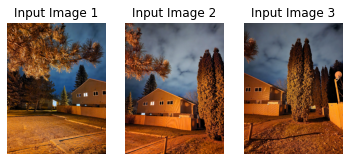

Stitching images 1 and 2...
Stitching images 2 and 3...


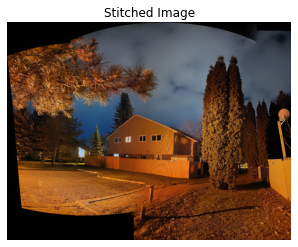

Stitching completed successfully.


In [4]:
if __name__ == "__main__":
    # List of image files to be stitched
    image_files = ['img11.jpg', 'img22.jpg', 'img33.jpg']

    images = []
    try:
        # Reading and processing each image
        for img_file in image_files:
            print(f"Reading image: {img_file}")
            img = cv2.imread(img_file)
            if img is not None:
                optimized_resolution = get_optimized_resolution(img.shape)
                if optimized_resolution is not None:
                    img = cv2.resize(img, (optimized_resolution[0], optimized_resolution[1]))
                    images.append(img)
                    print(f"Image read successfully: {img_file}")
                else:
                    print(f"Error getting optimized resolution for image: {img_file}")
            else:
                print(f"Error reading image: {img_file}")
    except Exception as e:
        print(f"Error processing images: {e}")

    if images:
        # Displaying input images
        for i, image in enumerate(images):
            plt.subplot(1, len(images), i + 1)
            plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            plt.title(f"Input Image {i + 1}")
            plt.axis('off')
        plt.show()

        # Stitching images and displaying the result
        result_image = stitch_images(images)

        if result_image is not None:
            cv2.imwrite("stitched_image.jpg", result_image)
            plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
            plt.title("Stitched Image")
            plt.axis('off')
            plt.show()
            print("Stitching completed successfully.")
        else:
            print("Error in stitching images. Result image is None.")
    else:
        print("No valid images to process.")
